In [ ]:
#VISULAIZER 
'''
1. DATASET VISUALIZER - Sample of word dataset + Dataset content flowchart
2. EPOCH VISUALIZER 
3. TRAINING DATASET VISUALIZER 
'''

using 4 case(s): ['word_0001', 'word_0007', 'word_0015', 'word_0025']

word_0001
  shape (Z,H,W): (173, 512, 512)
  spacing (mm):  (0.977, 0.977, 3.0)
  HU range:      -1024 .. 3065
  labels present: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]
  organs: ['liver', 'spleen', 'kidney (L)', 'kidney (R)', 'stomach', 'gallbladder', 'esophagus', 'pancreas', 'duodenum', 'colon', 'intestine', 'adrenal', 'rectum', 'bladder', 'head of femur (L)', 'head of femur (R)']
  richest slice: z=134 (11 organs)

word_0007
  shape (Z,H,W): (223, 512, 512)
  spacing (mm):  (0.977, 0.977, 3.0)
  HU range:      -1024 .. 2618
  labels present: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]
  organs: ['liver', 'spleen', 'kidney (L)', 'kidney (R)', 'stomach', 'gallbladder', 'esophagus', 'pancreas', 'duodenum', 'colon', 'intestine', 'adrenal', 'rectum', 'bladder', 'head of femur (L)', 'head of femur (R)']
  richest slice: z=169 (10 organs)

word_0015
  shape (Z,H,W): (224, 512, 512)
  spacing 

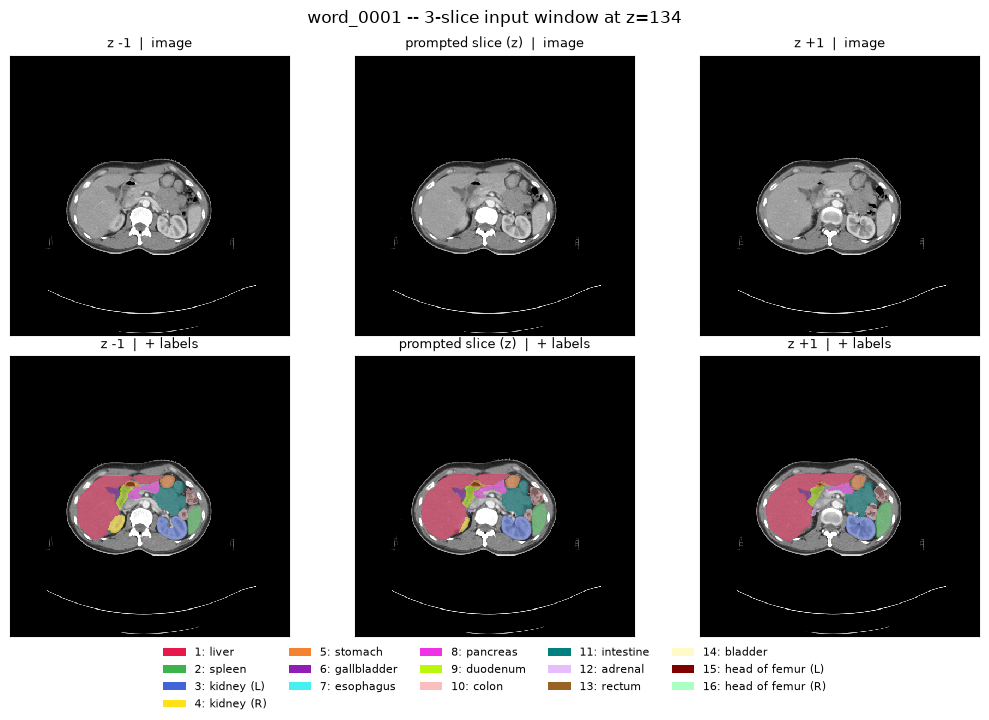

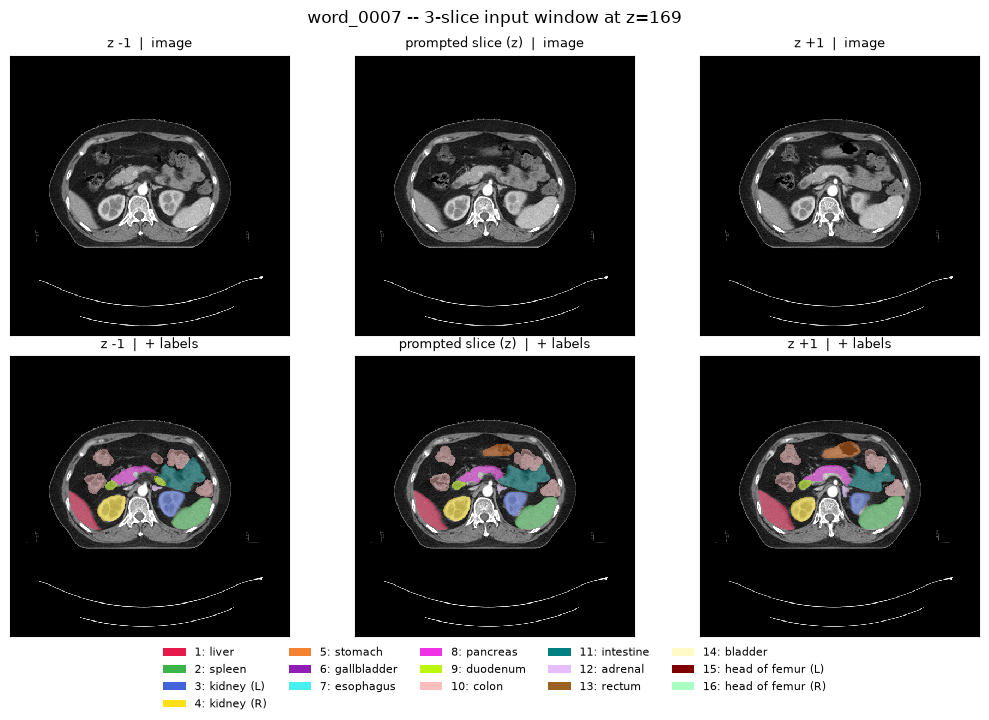

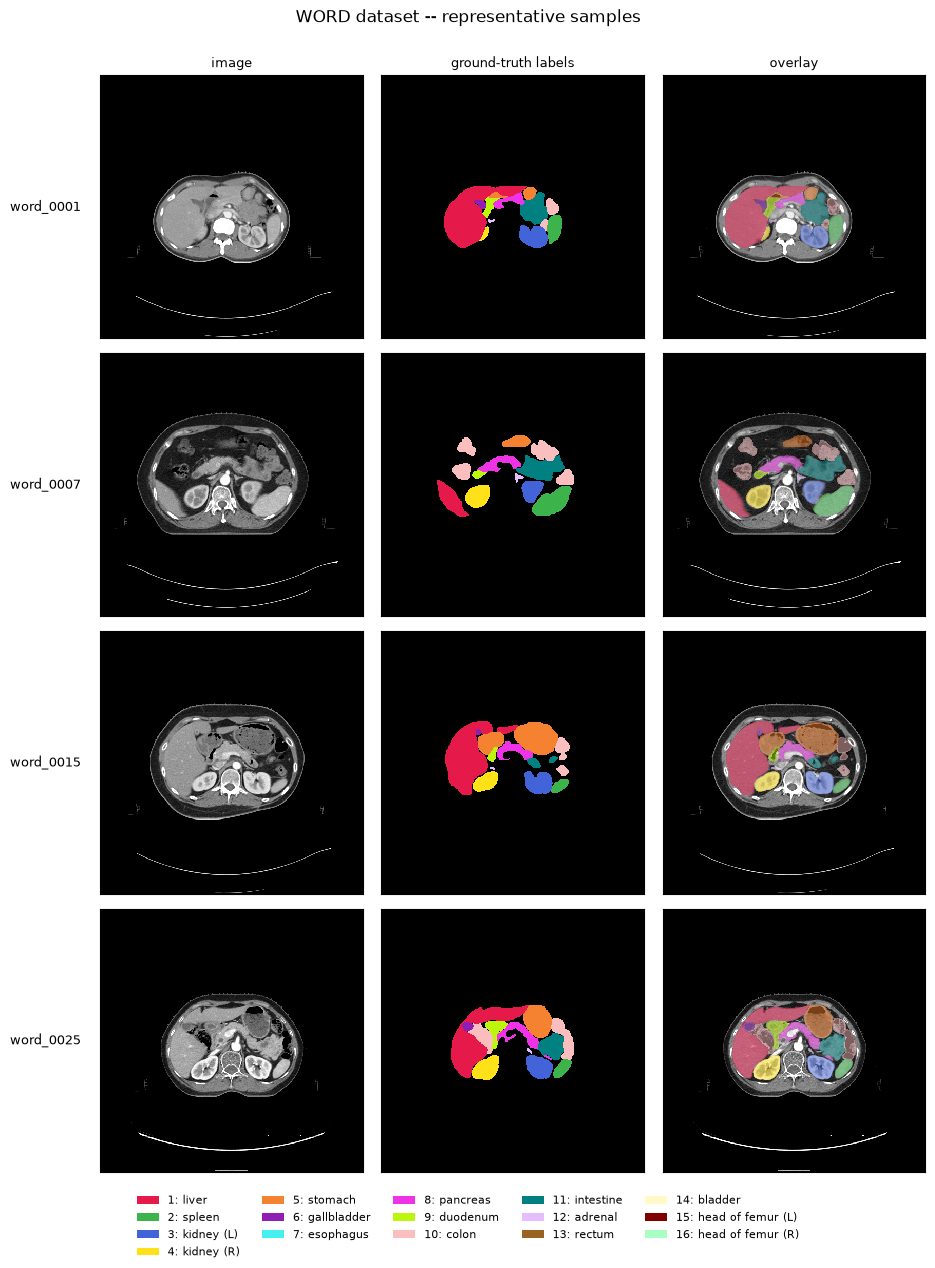

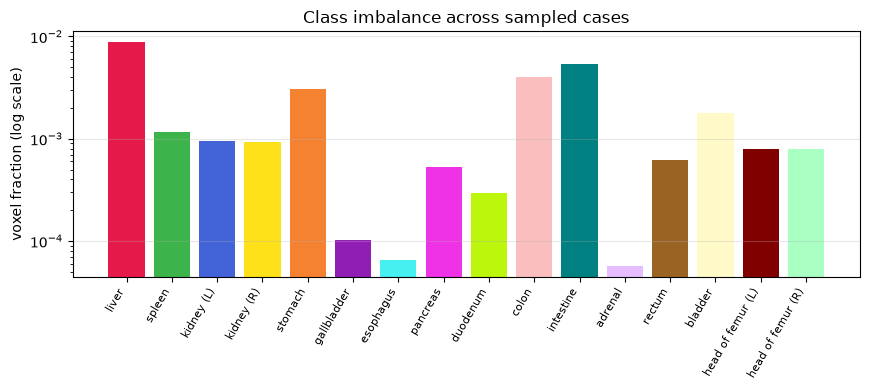

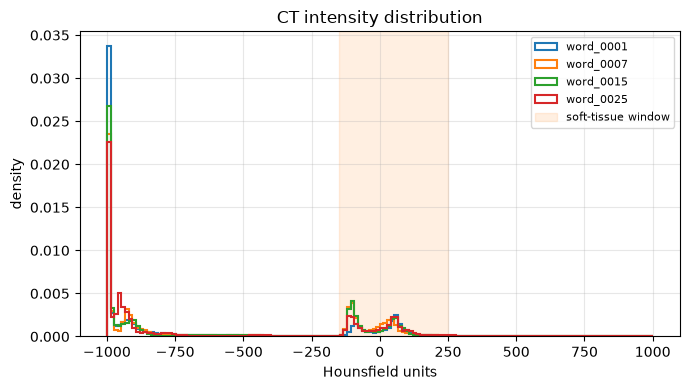

In [2]:
"""
dataset_viz.py
--------------
Visualizes a small representative sample of the WORD dataset.

Usage:
    python3 dataset_viz.py                     # auto-picks a few cases
    python3 dataset_viz.py word_0001 word_0007 # specific cases

Produces, in figures/:
    dataset_inspect.txt        shapes, spacing, label ids present
    dataset_triplet_<case>.png the 3-slice window Slide-SAM consumes
    dataset_grid.png           image | mask | overlay, one row per case
    dataset_class_balance.png  voxel fraction per organ (log scale)
    dataset_intensity.png      HU distribution
"""

import os
import sys
import glob
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

ROOT = os.path.expanduser(
    "~/Slide-SAM/Slide-SAM/datasets/07_WORD/WORD-V0.1.0")
OUT = "figures"

# WORD v0.1.0 organ labels
WORD_LABELS = {
    1: "liver", 2: "spleen", 3: "kidney (L)", 4: "kidney (R)",
    5: "stomach", 6: "gallbladder", 7: "esophagus", 8: "pancreas",
    9: "duodenum", 10: "colon", 11: "intestine", 12: "adrenal",
    13: "rectum", 14: "bladder", 15: "head of femur (L)",
    16: "head of femur (R)",
}

PALETTE = ["#e6194b", "#3cb44b", "#4363d8", "#ffe119", "#f58231",
           "#911eb4", "#46f0f0", "#f032e6", "#bcf60c", "#fabebe",
           "#008080", "#e6beff", "#9a6324", "#fffac8", "#800000",
           "#aaffc3"]


def find_pairs(cases=None, split="Va"):
    """Return [(name, image_path, label_path), ...]"""
    img_dir = os.path.join(ROOT, f"images{split}")
    lab_dir = os.path.join(ROOT, f"labels{split}")
    imgs = sorted(glob.glob(os.path.join(img_dir, "*.nii.gz")))
    pairs = []
    for p in imgs:
        name = os.path.basename(p).replace(".nii.gz", "")
        if cases and name not in cases:
            continue
        lab = os.path.join(lab_dir, os.path.basename(p))
        if os.path.exists(lab):
            pairs.append((name, p, lab))
    return pairs


def load(img_path, lab_path):
    im, la = nib.load(img_path), nib.load(lab_path)
    vol = np.asarray(im.dataobj, dtype=np.float32)
    lab = np.asarray(la.dataobj).astype(np.int16)
    spacing = im.header.get_zooms()[:3]
    # NIfTI is (X, Y, Z); move to (Z, H, W) so slices index on axis 0
    vol = np.transpose(vol, (2, 1, 0))
    lab = np.transpose(lab, (2, 1, 0))
    return vol, lab, spacing


def window(img, lo=-150, hi=250):
    """CT abdominal soft-tissue window, then scale to 0-1."""
    return np.clip((img - lo) / (hi - lo), 0, 1)


def cmap_for(ids):
    colors = ["#00000000"] + [PALETTE[(i - 1) % len(PALETTE)] for i in ids]
    return ListedColormap(colors)


def draw(ax, img, mask=None, ids=None, alpha=0.5, title=None):
    ax.imshow(window(img), cmap="gray", interpolation="nearest")
    if mask is not None and ids:
        remap = np.zeros_like(mask)
        for k, i in enumerate(ids, start=1):
            remap[mask == i] = k
        ax.imshow(np.ma.masked_where(remap == 0, remap),
                  cmap=cmap_for(ids), vmin=0, vmax=len(ids),
                  alpha=alpha, interpolation="nearest")
    ax.set_xticks([]); ax.set_yticks([])
    if title:
        ax.set_title(title, fontsize=9)


def busiest_slice(lab):
    """The slice with the most distinct organs -- best for a figure."""
    counts = [len(np.unique(lab[z])) for z in range(lab.shape[0])]
    return int(np.argmax(counts))


def legend_handles(ids):
    from matplotlib.patches import Patch
    return [Patch(facecolor=PALETTE[(i - 1) % len(PALETTE)],
                  label=f"{i}: {WORD_LABELS.get(i, '?')}") for i in ids]


def triplet(vol, lab, z, ids, name):
    """The exact 3-slice window Slide-SAM takes as input."""
    fig, axes = plt.subplots(2, 3, figsize=(10.5, 7.2))
    for j, off in (0, -1), (1, 0), (2, 1):
        zz = int(np.clip(z + off, 0, vol.shape[0] - 1))
        tag = "prompted slice (z)" if off == 0 else f"z {off:+d}"
        draw(axes[0, j], vol[zz], None, ids, title=f"{tag}  |  image")
        draw(axes[1, j], vol[zz], lab[zz], ids, title=f"{tag}  |  + labels")
    fig.legend(handles=legend_handles(ids), loc="lower center",
               ncol=min(len(ids), 5), fontsize=8, frameon=False)
    fig.suptitle(f"{name} -- 3-slice input window at z={z}", fontsize=12)
    fig.tight_layout(rect=[0, 0.09, 1, 1])
    plt.show()

def grid(samples, ids):
    n = len(samples)
    fig, axes = plt.subplots(n, 3, figsize=(9.5, 3.2 * n), squeeze=False)
    for i, (name, img, msk) in enumerate(samples):
        draw(axes[i][0], img, None, ids, title="image" if i == 0 else None)
        remap = np.zeros_like(msk)
        for k, cid in enumerate(ids, start=1):
            remap[msk == cid] = k
        axes[i][1].imshow(np.ma.masked_where(remap == 0, remap),
                          cmap=cmap_for(ids), vmin=0, vmax=len(ids),
                          interpolation="nearest")
        axes[i][1].set_facecolor("black")
        axes[i][1].set_xticks([]); axes[i][1].set_yticks([])
        if i == 0:
            axes[i][1].set_title("ground-truth labels", fontsize=9)
        draw(axes[i][2], img, msk, ids, title="overlay" if i == 0 else None)
        axes[i][0].set_ylabel(name, fontsize=9, rotation=0,
                              ha="right", va="center", labelpad=14)
    fig.legend(handles=legend_handles(ids), loc="lower center",
               ncol=min(len(ids), 5), fontsize=8, frameon=False)
    fig.suptitle("WORD dataset -- representative samples", fontsize=12)
    fig.tight_layout(rect=[0, 0.06, 1, 0.98])
    plt.show()


def class_balance(all_labels, ids):
    counts = {i: 0 for i in ids}
    total = 0
    for lab in all_labels:
        u, c = np.unique(lab, return_counts=True)
        total += lab.size
        for uu, cc in zip(u, c):
            if uu in counts:
                counts[uu] += cc
    frac = [counts[i] / total for i in ids]
    fig, ax = plt.subplots(figsize=(max(6, 0.55 * len(ids)), 4))
    ax.bar([WORD_LABELS.get(i, str(i)) for i in ids], frac,
           color=[PALETTE[(i - 1) % len(PALETTE)] for i in ids])
    ax.set_yscale("log")
    ax.set_ylabel("voxel fraction (log scale)")
    ax.set_title("Class imbalance across sampled cases")
    ax.tick_params(axis="x", rotation=60, labelsize=8)
    for t in ax.get_xticklabels():
        t.set_ha("right")
    ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    plt.show()


def intensity(vols, names):
    fig, ax = plt.subplots(figsize=(7, 4))
    for v, n in zip(vols, names):
        s = v[::4, ::4, ::4].ravel()
        ax.hist(s, bins=150, range=(-1000, 1000), histtype="step",
                density=True, lw=1.5, label=n)
    ax.axvspan(-150, 250, color="tab:orange", alpha=0.12,
               label="soft-tissue window")
    ax.set_xlabel("Hounsfield units")
    ax.set_ylabel("density")
    ax.set_title("CT intensity distribution")
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()


def main(cases):
    pairs = find_pairs(cases)
    if not pairs:
        print(f"no image/label pairs found under {ROOT}")
        return
    pairs = pairs[:4]
    print(f"using {len(pairs)} case(s): {[p[0] for p in pairs]}\n")

    lines, samples, all_labels, vols, names = [], [], [], [], []
    id_set = set()

    for name, ip, lp in pairs:
        vol, lab, sp = load(ip, lp)
        ids = [int(i) for i in np.unique(lab) if i != 0]
        id_set.update(ids)
        z = busiest_slice(lab)
        info = (f"{name}\n"
                f"  shape (Z,H,W): {vol.shape}\n"
                f"  spacing (mm):  {tuple(round(float(s), 3) for s in sp)}\n"
                f"  HU range:      {vol.min():.0f} .. {vol.max():.0f}\n"
                f"  labels present: {ids}\n"
                f"  organs: {[WORD_LABELS.get(i, '?') for i in ids]}\n"
                f"  richest slice: z={z} ({len(np.unique(lab[z]))-1} organs)\n")
        print(info)
        lines.append(info)
        samples.append((name, vol[z], lab[z]))
        all_labels.append(lab)
        vols.append(vol); names.append(name)

    ids = sorted(id_set)
    for (name, ip, lp) in pairs[:2]:
        vol, lab, _ = load(ip, lp)
        triplet(vol, lab, busiest_slice(lab), ids, name)
    grid(samples, ids)
    class_balance(all_labels, ids)
    intensity(vols, names)


main(None)

  read word_0002.nii.gz
  read word_0003.nii.gz
  read word_0004.nii.gz
  read word_0005.nii.gz
      train: 100 cases, 100 labelled, 20115 slices
       test: 30 cases, 30 labelled, 6277 slices
 validation: 20 cases, 20 labelled, 4103 slices


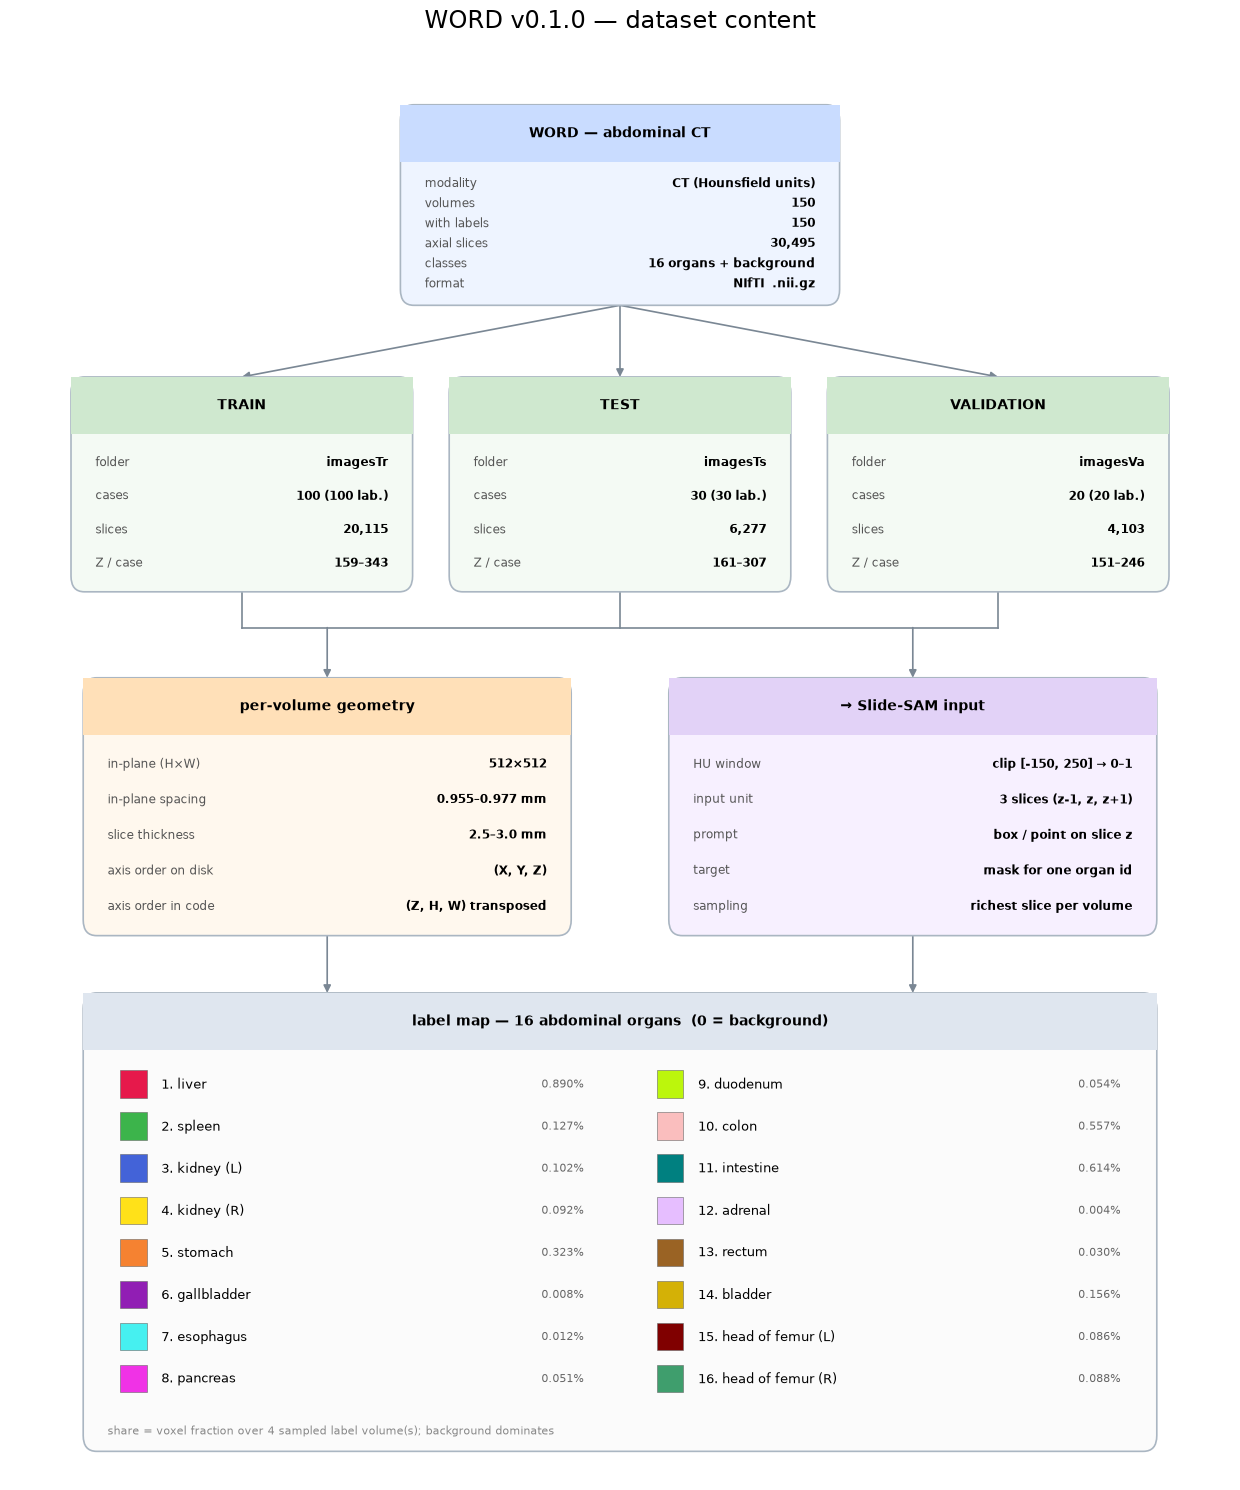

In [3]:
# ── WORD dataset content flowchart ─────────────────────────────────────────
import os, glob, json
import numpy as np, nibabel as nib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle, FancyArrowPatch

ROOT = os.path.expanduser("~/Slide-SAM/Slide-SAM/datasets/07_WORD/WORD-V0.1.0")
OUT, CACHE = "figures", "figures/dataset_stats.json"
LABEL_CASES = 4          # label volumes actually loaded (for organ shares)
RESCAN      = False      # True to ignore the cache

WORD_LABELS = {1:"liver",2:"spleen",3:"kidney (L)",4:"kidney (R)",5:"stomach",
               6:"gallbladder",7:"esophagus",8:"pancreas",9:"duodenum",
               10:"colon",11:"intestine",12:"adrenal",13:"rectum",14:"bladder",
               15:"head of femur (L)",16:"head of femur (R)"}
PALETTE = ["#e6194b","#3cb44b","#4363d8","#ffe119","#f58231","#911eb4",
           "#46f0f0","#f032e6","#bcf60c","#fabebe","#008080","#e6beff",
           "#9a6324","#d4b106","#800000","#3f9e6d"]
PRETTY = {"tr":"train","va":"validation","val":"validation","ts":"test","te":"test"}


def scan(root=ROOT, label_cases=LABEL_CASES, rescan=RESCAN):
    os.makedirs(OUT, exist_ok=True)
    if os.path.exists(CACHE) and not rescan:
        return json.load(open(CACHE))

    stats = {"splits": {}, "organs": {}, "n_label_cases": 0}
    vox = {i: 0 for i in WORD_LABELS}; seen = {i: 0 for i in WORD_LABELS}
    total = 0; budget = label_cases

    for d in sorted(glob.glob(os.path.join(root, "images*"))):
        if not os.path.isdir(d): continue
        suf = os.path.basename(d)[6:]
        ldir = os.path.join(root, f"labels{suf}")
        imgs = sorted(glob.glob(os.path.join(d, "*.nii.gz")))
        zs, hw, sxy, sz, nlab = [], set(), [], [], 0

        for p in imgs:
            h = nib.load(p).header                      # header only = fast
            s, z = h.get_data_shape()[:3], h.get_zooms()[:3]
            zs.append(int(s[2])); hw.add((int(s[1]), int(s[0])))
            sxy.append(float(z[0])); sz.append(float(z[2]))
            lp = os.path.join(ldir, os.path.basename(p))
            if os.path.exists(lp):
                nlab += 1
                if budget > 0:                          # only these get loaded
                    lab = np.asarray(nib.load(lp).dataobj).astype(np.int16)
                    u, c = np.unique(lab, return_counts=True)
                    total += int(lab.size)
                    for uu, cc in zip(u, c):
                        if int(uu) in vox: vox[int(uu)] += int(cc); seen[int(uu)] += 1
                    budget -= 1; stats["n_label_cases"] += 1
                    print(f"  read {os.path.basename(lp)}")

        stats["splits"][suf] = dict(
            name=PRETTY.get(suf.lower(), suf), n_cases=len(imgs), n_labelled=nlab,
            total_slices=int(sum(zs)), z_range=[min(zs), max(zs)] if zs else None,
            inplane=sorted(hw)[:2],
            spacing_xy=[round(min(sxy),3), round(max(sxy),3)] if sxy else None,
            spacing_z=[round(min(sz),3), round(max(sz),3)] if sz else None)
        print(f"{stats['splits'][suf]['name']:>11}: {len(imgs)} cases, "
              f"{nlab} labelled, {sum(zs)} slices")

    for i in WORD_LABELS:
        stats["organs"][str(i)] = dict(name=WORD_LABELS[i], voxels=vox[i],
                                       frac=vox[i]/total if total else 0.0,
                                       cases_seen=seen[i])
    json.dump(stats, open(CACHE, "w"), indent=2)
    return stats


def _box(ax, x, y, w, h, title, rows, fill, head):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0,rounding_size=1.1",
                                fc=fill, ec="#aab6c2", lw=1.2, zorder=2))
    hh = 4.0
    ax.add_patch(Rectangle((x, y+h-hh), w, hh, fc=head, ec="none", zorder=3))
    ax.text(x+w/2, y+h-hh/2, title, ha="center", va="center",
            fontsize=10, fontweight="bold", zorder=4)
    top, step = y+h-hh-0.8, (h-hh-1.6)/max(len(rows), 1)
    for i, (k, v) in enumerate(rows):
        yy = top - step*(i+0.5)
        ax.text(x+2, yy, k, ha="left", va="center", fontsize=8.3, color="#555", zorder=4)
        ax.text(x+w-2, yy, v, ha="right", va="center", fontsize=8.3,
                fontweight="bold", zorder=4)


def _arrow(ax, p, q):
    ax.add_patch(FancyArrowPatch(p, q, arrowstyle="-|>", mutation_scale=11,
                                 color="#7a8794", lw=1.2, shrinkA=0, shrinkB=0,
                                 zorder=1))


def draw(stats):
    S = stats["splits"]
    tc = sum(s["n_cases"] for s in S.values())
    tl = sum(s["n_labelled"] for s in S.values())
    ts = sum(s["total_slices"] for s in S.values())

    fig, ax = plt.subplots(figsize=(12.5, 15))
    ax.set_xlim(0, 100); ax.set_ylim(0, 100); ax.axis("off")
    ax.set_title("WORD v0.1.0 — dataset content", fontsize=17, pad=14)

    _box(ax, 32, 82, 36, 14, "WORD — abdominal CT",
         [("modality", "CT (Hounsfield units)"), ("volumes", f"{tc}"),
          ("with labels", f"{tl}"), ("axial slices", f"{ts:,}"),
          ("classes", f"{len(WORD_LABELS)} organs + background"),
          ("format", "NIfTI  .nii.gz")], "#eef4ff", "#c9dcff")

    n = len(S); w = min(28, 92/n); gap = (96 - n*w)/(n+1)
    centers = []
    for i, (suf, s) in enumerate(S.items()):
        x = 2 + gap + i*(w+gap); zr = s["z_range"]
        _box(ax, x, 62, w, 15, s["name"].upper(),
             [("folder", f"images{suf}"), ("cases", f"{s['n_cases']} ({s['n_labelled']} lab.)"),
              ("slices", f"{s['total_slices']:,}"),
              ("Z / case", f"{zr[0]}–{zr[1]}" if zr else "—")], "#f4faf4", "#cfe8cf")
        centers.append(x+w/2)
        _arrow(ax, (50, 82), (x+w/2, 77))

    a = next(iter(S.values()))
    ip = ", ".join(f"{h}×{ww}" for h, ww in a["inplane"]) or "—"
    sxy, sz = a["spacing_xy"], a["spacing_z"]
    _box(ax, 6, 38, 40, 18, "per-volume geometry",
         [("in-plane (H×W)", ip),
          ("in-plane spacing", f"{sxy[0]}–{sxy[1]} mm" if sxy else "—"),
          ("slice thickness", f"{sz[0]}–{sz[1]} mm" if sz else "—"),
          ("axis order on disk", "(X, Y, Z)"),
          ("axis order in code", "(Z, H, W) transposed")], "#fff8ee", "#ffe0b8")

    _box(ax, 54, 38, 40, 18, "→ Slide-SAM input",
         [("HU window", "clip [-150, 250] → 0–1"),
          ("input unit", "3 slices (z-1, z, z+1)"),
          ("prompt", "box / point on slice z"),
          ("target", "mask for one organ id"),
          ("sampling", "richest slice per volume")], "#f7f0ff", "#e2d2f7")

    ax.plot([min(centers), max(centers)], [59.5, 59.5], color="#7a8794", lw=1.2, zorder=1)
    for c in centers:
        ax.plot([c, c], [62, 59.5], color="#7a8794", lw=1.2, zorder=1)
    _arrow(ax, (26, 59.5), (26, 56)); _arrow(ax, (74, 59.5), (74, 56))

    # organ table
    x0, y0, W, H = 6, 2, 88, 32
    ax.add_patch(FancyBboxPatch((x0, y0), W, H, boxstyle="round,pad=0,rounding_size=1.1",
                                fc="#fbfbfb", ec="#aab6c2", lw=1.2, zorder=2))
    ax.add_patch(Rectangle((x0, y0+H-4), W, 4, fc="#dfe6ef", ec="none", zorder=3))
    ax.text(x0+W/2, y0+H-2, "label map — 16 abdominal organs  (0 = background)",
            ha="center", va="center", fontsize=10, fontweight="bold", zorder=4)
    rows, colw = 8, W/2
    for k, i in enumerate(sorted(WORD_LABELS)):
        r, c = k % rows, k // rows
        cx = x0 + 3 + c*colw
        cy = y0 + H - 6.4 - r*((H-8.5)/rows)
        o = stats["organs"][str(i)]; pct = o["frac"]*100
        ax.add_patch(Rectangle((cx, cy-0.9), 2.2, 1.9, fc=PALETTE[(i-1) % 16],
                               ec="#666", lw=0.4, zorder=4))
        ax.text(cx+3.4, cy, f"{i}. {o['name']}", ha="left", va="center",
                fontsize=9, zorder=4)
        ax.text(cx+colw-6, cy, f"{pct:.3f}%" if pct >= 0.001 else "<0.001%",
                ha="right", va="center", fontsize=8, color="#666", zorder=4)
    ax.text(x0+2, y0+1.4, f"share = voxel fraction over {stats['n_label_cases']} "
            f"sampled label volume(s); background dominates",
            ha="left", va="center", fontsize=8, color="#888", zorder=4)
    _arrow(ax, (26, 38), (26, 34)); _arrow(ax, (74, 38), (74, 34))

    fig.tight_layout()
    os.makedirs(OUT, exist_ok=True)
    fig.savefig(f"{OUT}/dataset_flowchart.png", dpi=200, bbox_inches="tight")
    fig.savefig(f"{OUT}/dataset_flowchart.svg", bbox_inches="tight")
    plt.show()


draw(scan())

source: TensorBoard  —  15 scalar series
  train [box_loss]                                        5 pts   0.1841 … 0.2604
  train [dl]                                              5 pts   0.1542 … 0.2108
  train [fl]                                              5 pts   0.001368 … 0.002016
  train [loss]                                            5 pts   0.4192 … 0.6529
  train [lr]                                              5 pts   5e-06 … 0.0002
  train [min_losses]                                      5 pts   0.1815 … 0.2512
  train [point_loss]                                      5 pts   0.2352 … 0.3924
  train [selected_losses]                                 5 pts   0.002558 … 0.00927
  train [time_batch]                                      5 pts   0.4061 … 0.7662
  train [time_bp]                                         5 pts   0.2524 … 0.4808
  train [time_cuda]                                       5 pts   0.002143 … 0.0042
  train [time_forward]                           

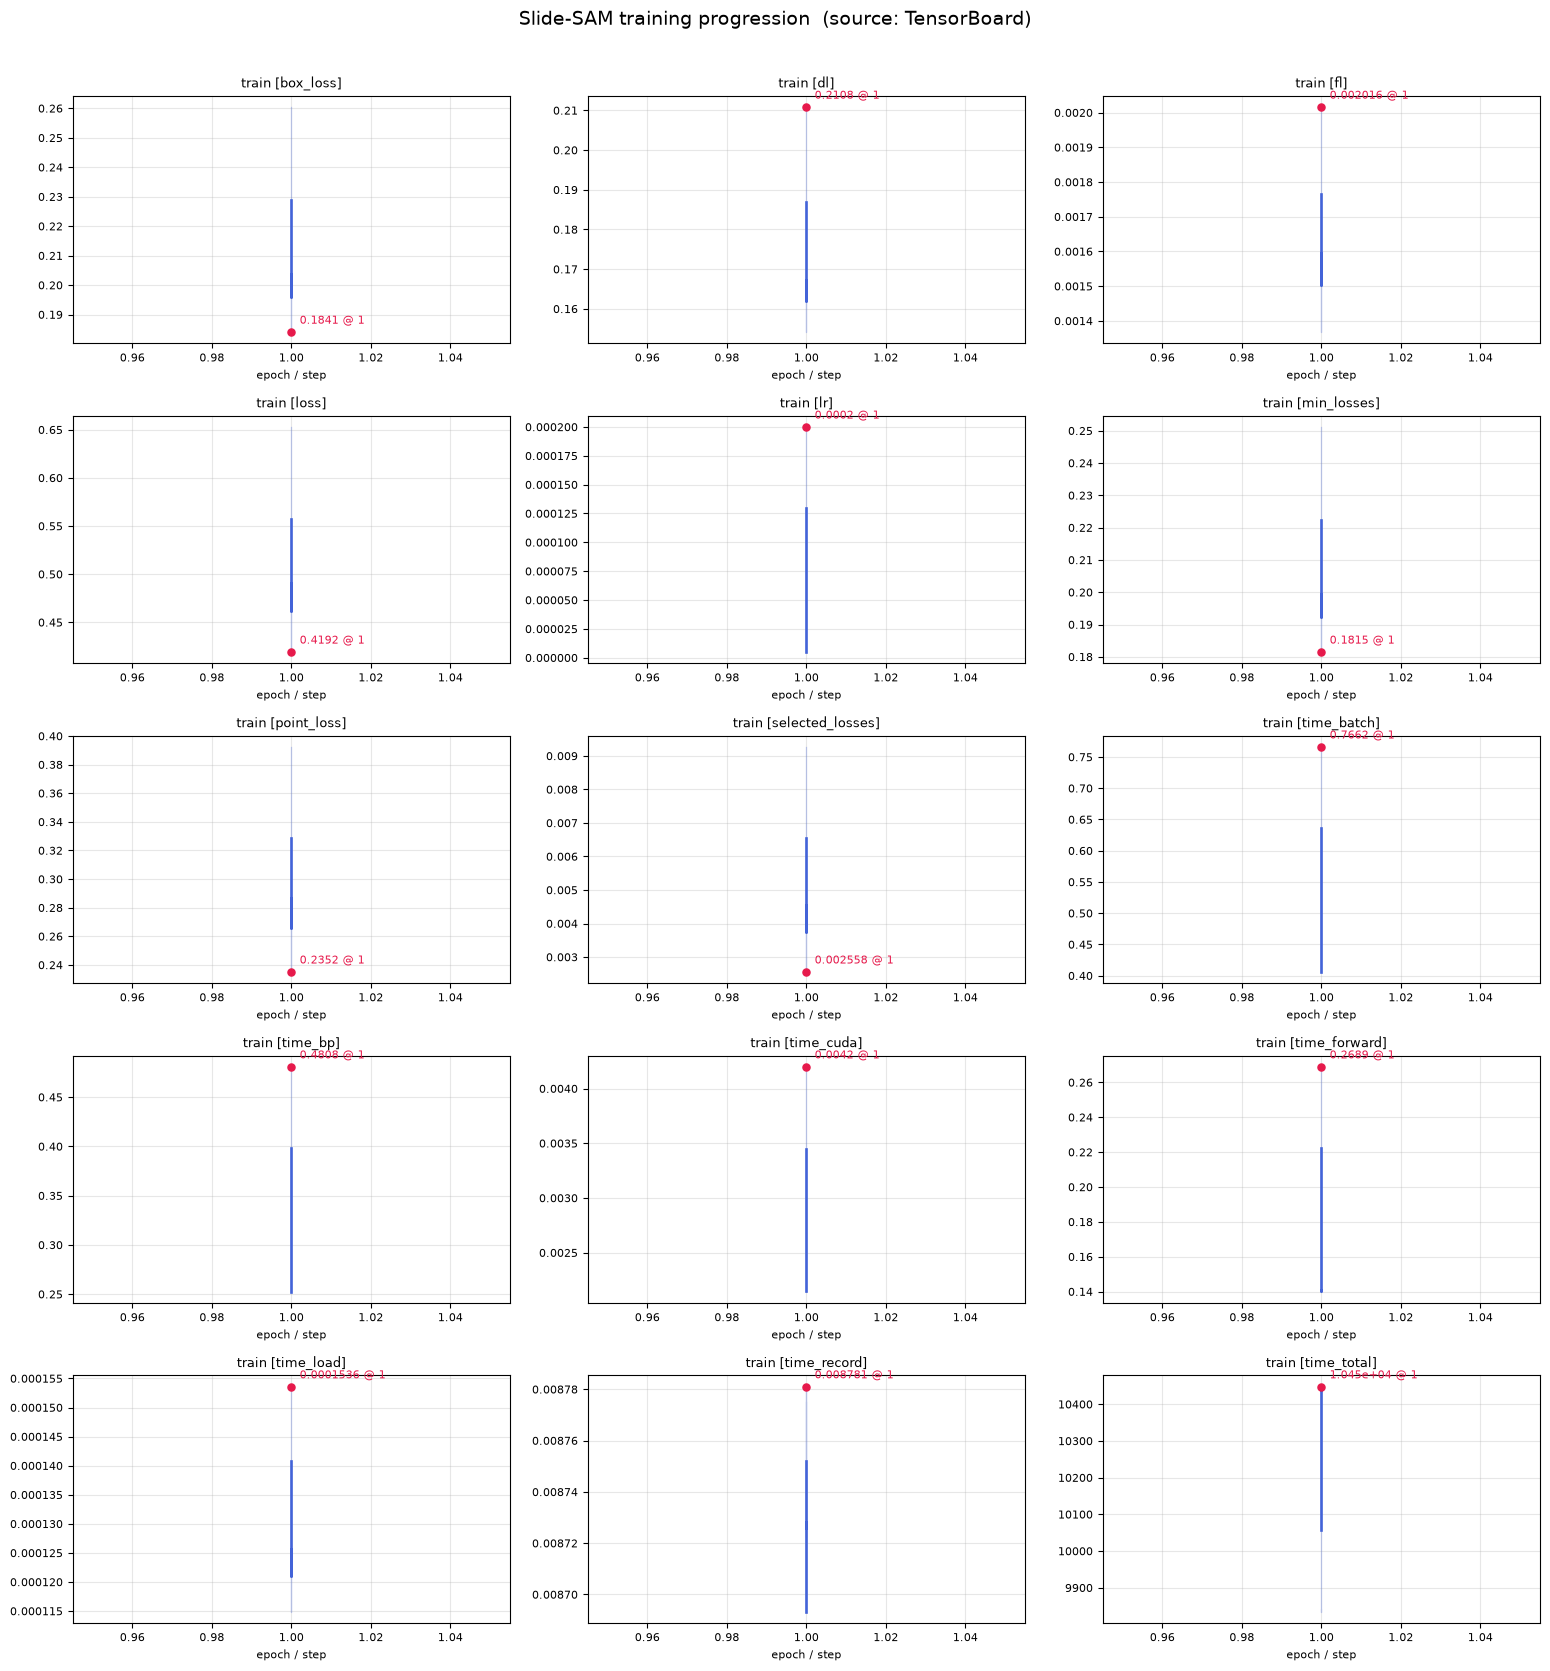

In [4]:
# ── epoch curves: auto-discovers TB scalars, falls back to log parsing ─────
import os, re, glob, math
import numpy as np, matplotlib.pyplot as plt

HOME, OUT = os.path.expanduser("~/Slide-SAM/Slide-SAM"), "figures"
SMOOTH = 0.6            # EMA weight, 0 = off

def from_tensorboard():
    ev = set(glob.glob(os.path.join(HOME, "**", "events.out.tfevents.*"), recursive=True))
    ev |= set(glob.glob(os.path.expanduser("~/Slide-SAM/runs/**/events.out.tfevents.*"),
                        recursive=True))
    if not ev: return {}
    from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
    series = {}
    for e in sorted(ev):
        run = os.path.basename(os.path.dirname(e))
        try:
            acc = EventAccumulator(e, size_guidance={"scalars": 0}); acc.Reload()
        except Exception:
            continue
        for tag in acc.Tags()["scalars"]:
            pts = acc.Scalars(tag)
            key = f"{tag}" if len(ev) == 1 else f"{tag} [{run}]"
            series.setdefault(key, ([], []))
            series[key][0].extend(p.step for p in pts)
            series[key][1].extend(p.value for p in pts)
    return series

def from_logs():
    series, epoch = {}, 0
    pat = re.compile(r"([A-Za-z_][A-Za-z0-9_/\.]*)\s*[:=]\s*([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?)")
    for lg in sorted(glob.glob(os.path.join(HOME, "*.log"))
                     + glob.glob(os.path.join(HOME, "logs", "**", "*.log"), recursive=True)):
        run = os.path.basename(lg).replace(".log", "")
        for line in open(lg, errors="ignore"):
            found = dict(pat.findall(line))
            for k in list(found):
                if k.lower() in ("epoch", "ep"):
                    epoch = float(found[k])
            for k, v in found.items():
                if k.lower() in ("epoch", "ep", "iter", "step", "lr_step"): continue
                try: v = float(v)
                except ValueError: continue
                if not math.isfinite(v): continue
                key = f"{k} [{run}]"
                series.setdefault(key, ([], []))
                series[key][0].append(epoch); series[key][1].append(v)
    return series

def ema(y, w):
    if w <= 0: return y
    out, last = [], y[0]
    for v in y:
        last = last * w + v * (1 - w); out.append(last)
    return out

series = from_tensorboard(); src = "TensorBoard"
if not series:
    series = from_logs(); src = "log files"
series = {k: v for k, v in series.items() if len(v[1]) > 1}
print(f"source: {src}  —  {len(series)} scalar series")
for k, (x, y) in sorted(series.items()):
    print(f"  {k:<50} {len(y):>6} pts   {min(y):.4g} … {max(y):.4g}")

if series:
    keys = sorted(series)
    n = len(keys); cols = min(3, n); rows = -(-n // cols)
    fig, axes = plt.subplots(rows, cols, figsize=(5.2*cols, 3.4*rows), squeeze=False)
    for i, k in enumerate(keys):
        ax = axes[i // cols][i % cols]
        x, y = series[k]
        o = np.argsort(x); x, y = np.array(x)[o], np.array(y)[o]
        ax.plot(x, y, lw=0.9, alpha=0.30, color="#4363d8")
        ax.plot(x, ema(list(y), SMOOTH), lw=1.9, color="#4363d8")
        best = (np.argmin(y) if any(t in k.lower() for t in ("loss", "err"))
                else np.argmax(y))
        ax.scatter([x[best]], [y[best]], s=26, color="#e6194b", zorder=5)
        ax.annotate(f"{y[best]:.4g} @ {x[best]:.0f}", (x[best], y[best]),
                    textcoords="offset points", xytext=(6, 6), fontsize=8, color="#e6194b")
        ax.set_title(k, fontsize=9); ax.grid(alpha=0.3)
        ax.set_xlabel("epoch / step", fontsize=8); ax.tick_params(labelsize=8)
    for j in range(n, rows*cols): axes[j // cols][j % cols].axis("off")
    fig.suptitle(f"Slide-SAM training progression  (source: {src})", fontsize=14)
    fig.tight_layout(rect=[0, 0, 1, 0.97])
    os.makedirs(OUT, exist_ok=True)
    fig.savefig(f"{OUT}/epoch_curves.png", dpi=180, bbox_inches="tight")
    plt.show()
else:
    print("nothing found — paste the inventory dump and I'll target it directly")

checkpoints: [(0, 'model_epoch_0.pth'), (1, 'model_epoch_1.pth')]
cases: [('word_0002', 'z=209'), ('word_0003', 'z=150')]


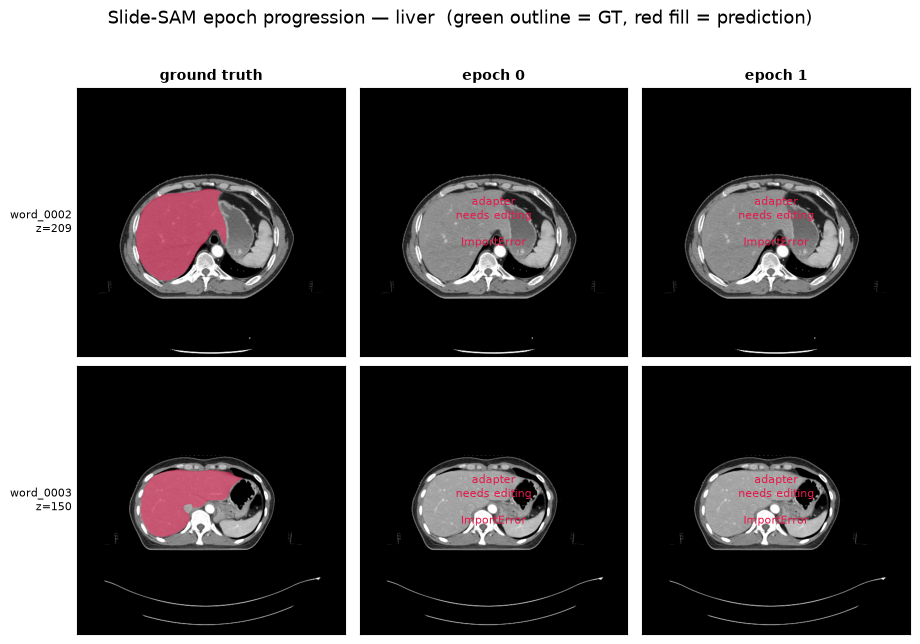

In [7]:
# ── epoch progression: GT | epoch 1 | epoch 2 | epoch 3 ───────────────────
import os, re, glob
import numpy as np, nibabel as nib, matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

HOME  = os.path.expanduser("~/Slide-SAM/Slide-SAM")
DROOT = os.path.join(HOME, "datasets/07_WORD/WORD-V0.1.0")
OUT   = "figures"
ORGAN = 1          # which organ id to track (1 = liver)
N_CASES = 2        # rows in the figure
DEVICE = "cuda"

WORD_LABELS = {1:"liver",2:"spleen",3:"kidney (L)",4:"kidney (R)",5:"stomach",
               6:"gallbladder",7:"esophagus",8:"pancreas",9:"duodenum",10:"colon",
               11:"intestine",12:"adrenal",13:"rectum",14:"bladder",
               15:"head of femur (L)",16:"head of femur (R)"}

# ═══════════════ ADAPTER — the only repo-specific part ════════════════════
_CACHE = {}

def load_model(ckpt_path):
    """Return a model ready for inference from a checkpoint path."""
    if ckpt_path in _CACHE: return _CACHE[ckpt_path]
    import torch
    # ---- EDIT ME: mirror whatever test/ or core/ does to build the model ----
    from modeling.build_sam import sam_model_registry        # ← likely wrong name
    model = sam_model_registry["vit_b"](checkpoint=None)
    sd = torch.load(ckpt_path, map_location="cpu")
    sd = sd.get("model", sd.get("state_dict", sd))
    sd = {k.replace("module.", ""): v for k, v in sd.items()}
    print("   ", model.load_state_dict(sd, strict=False))
    # ------------------------------------------------------------------------
    model.to(DEVICE).eval()
    _CACHE[ckpt_path] = model
    return model

def predict(model, triplet, box):
    """triplet: (3, H, W) float 0-1.  box: (x0, y0, x1, y1).
    Return a binary (H, W) mask for the CENTRE slice."""
    import torch
    with torch.no_grad():
        x = torch.from_numpy(triplet)[None].float().to(DEVICE)
        b = torch.tensor(box)[None][None].float().to(DEVICE)
        # ---- EDIT ME: the real Slide-SAM call ----
        out = model(x, boxes=b)
        logits = out["masks"] if isinstance(out, dict) else out
        # ------------------------------------------
        m = torch.sigmoid(logits).squeeze().cpu().numpy()
        if m.ndim == 3: m = m[m.shape[0] // 2]
        return (m > 0.5).astype(np.uint8)
# ═══════════════════════════════════════════════════════════════════════════

def find_checkpoints():
    pats = [os.path.join(HOME, "weights", "*.pth"),
            os.path.join(HOME, "logs", "**", "*.pth"),
            os.path.expanduser("~/Slide-SAM/runs/**/*.pth")]
    hits = {}
    for p in pats:
        for f in glob.glob(p, recursive=True):
            m = re.search(r"(?:epoch|ep)[_\-]?(\d+)", os.path.basename(f), re.I)
            if m: hits.setdefault(int(m.group(1)), f)
    if not hits:
        print("no epoch-tagged checkpoints found. what's in weights/ ?")
        for f in glob.glob(os.path.join(HOME, "weights", "*")): print("   ", f)
    return [(e, hits[e]) for e in sorted(hits)]

def window(img, lo=-150, hi=250):
    return np.clip((img - lo) / (hi - lo), 0, 1)

def dice(a, b):
    s = a.sum() + b.sum()
    return 1.0 if s == 0 else 2.0 * (a & b).sum() / s

def bbox_of(mask, pad=8):
    ys, xs = np.where(mask)
    if len(xs) == 0: return None
    return (max(xs.min()-pad, 0), max(ys.min()-pad, 0),
            min(xs.max()+pad, mask.shape[1]-1), min(ys.max()+pad, mask.shape[0]-1))

def pick_cases(n, organ):
    idir = sorted(glob.glob(os.path.join(DROOT, "images*")))[0]
    suf  = os.path.basename(idir)[6:]
    out = []
    for p in sorted(glob.glob(os.path.join(idir, "*.nii.gz"))):
        lp = os.path.join(DROOT, f"labels{suf}", os.path.basename(p))
        if not os.path.exists(lp): continue
        lab = np.transpose(np.asarray(nib.load(lp).dataobj).astype(np.int16), (2,1,0))
        area = [(lab[z] == organ).sum() for z in range(lab.shape[0])]
        if max(area) < 200: continue
        z = int(np.argmax(area))
        vol = np.transpose(np.asarray(nib.load(p).dataobj, dtype=np.float32), (2,1,0))
        tri = np.stack([window(vol[np.clip(z+o, 0, vol.shape[0]-1)]) for o in (-1,0,1)])
        out.append((os.path.basename(p).replace(".nii.gz",""), tri,
                    (lab[z] == organ).astype(np.uint8), z))
        if len(out) >= n: break
    return out

ckpts = find_checkpoints()
print("checkpoints:", [(e, os.path.basename(f)) for e, f in ckpts])
cases = pick_cases(N_CASES, ORGAN)
print("cases:", [(c[0], f"z={c[3]}") for c in cases])

if ckpts and cases:
    cmap = ListedColormap(["#00000000", "#e6194b"])
    ncol = 1 + len(ckpts)
    fig, axes = plt.subplots(len(cases), ncol,
                             figsize=(3.1*ncol, 3.3*len(cases)), squeeze=False)
    scores = {}
    for r, (name, tri, gt, z) in enumerate(cases):
        box = bbox_of(gt)
        ax = axes[r][0]
        ax.imshow(tri[1], cmap="gray"); ax.set_xticks([]); ax.set_yticks([])
        ax.imshow(np.ma.masked_where(gt == 0, gt), cmap=cmap, vmin=0, vmax=1, alpha=0.55)
        ax.set_ylabel(f"{name}\nz={z}", fontsize=8, rotation=0, ha="right", va="center")
        if r == 0: ax.set_title("ground truth", fontsize=10, fontweight="bold")
        for c, (ep, path) in enumerate(ckpts, start=1):
            ax = axes[r][c]
            ax.imshow(tri[1], cmap="gray"); ax.set_xticks([]); ax.set_yticks([])
            try:
                pred = predict(load_model(path), tri, box)
                d = dice(pred.astype(bool), gt.astype(bool))
                scores.setdefault(ep, []).append(d)
                ax.imshow(np.ma.masked_where(pred == 0, pred), cmap=cmap, vmin=0, vmax=1, alpha=0.55)
                ax.contour(gt, levels=[0.5], colors="#3cb44b", linewidths=0.9)
                ax.set_xlabel(f"Dice {d:.3f}", fontsize=9)
            except Exception as e:
                ax.text(0.5, 0.5, f"adapter\nneeds editing\n\n{type(e).__name__}",
                        ha="center", va="center", transform=ax.transAxes,
                        fontsize=8, color="#e6194b")
            if r == 0: ax.set_title(f"epoch {ep}", fontsize=10, fontweight="bold")
    if scores:
        print("\nmean Dice:", {e: round(float(np.mean(v)), 4) for e, v in scores.items()})
    fig.suptitle(f"Slide-SAM epoch progression — {WORD_LABELS.get(ORGAN, ORGAN)}  "
                 f"(green outline = GT, red fill = prediction)", fontsize=13)
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    os.makedirs(OUT, exist_ok=True)
    fig.savefig(f"{OUT}/epoch_progression_organ{ORGAN}.png", dpi=180, bbox_inches="tight")
    plt.show()

In [6]:
# ── find Slide-SAM's real model builder + inference call ──────────────────
import os, re, glob
HOME = os.path.expanduser("~/Slide-SAM/Slide-SAM")

print("="*70, "\nDEFINITIONS worth importing\n" + "="*70)
pat = re.compile(r"^\s*(def (build\w*|sam_model_registry\w*|\w*model\w*)\b|"
                 r"class \w*(Sam|SAM|Slide)\w*\b|sam_model_registry\s*=)", re.M)
for f in glob.glob(os.path.join(HOME, "**", "*.py"), recursive=True):
    if "/datasets/" in f or "__pycache__" in f: continue
    try: src = open(f, errors="ignore").read()
    except Exception: continue
    hits = [(src[:m.start()].count("\n")+1, m.group(0).strip()) for m in pat.finditer(src)]
    if hits:
        print(f"\n--- {os.path.relpath(f, HOME)}")
        for ln, h in hits[:8]: print(f"   L{ln:<5} {h}")

print("\n" + "="*70, "\ntest/ and core/ contents\n" + "="*70)
for d in ("test", "core", "modeling"):
    for f in sorted(glob.glob(os.path.join(HOME, d, "**", "*.py"), recursive=True)):
        print("  ", os.path.relpath(f, HOME))

print("\n" + "="*70, "\nwhere checkpoints get LOADED (torch.load / load_state_dict)\n" + "="*70)
for f in glob.glob(os.path.join(HOME, "**", "*.py"), recursive=True):
    if "__pycache__" in f: continue
    try: lines = open(f, errors="ignore").readlines()
    except Exception: continue
    for i, l in enumerate(lines):
        if "load_state_dict" in l or "torch.load" in l:
            print(f"\n--- {os.path.relpath(f, HOME)}  L{i+1}")
            for j in range(max(0, i-6), min(len(lines), i+4)):
                print(("  > " if j == i else "    ") + lines[j].rstrip()[:120])
            break

print("\n" + "="*70, "\nkeys inside your checkpoint\n" + "="*70)
import torch
ck = os.path.join(HOME, "weights", "model_epoch_1.pth")
ck = ck if os.path.exists(ck) else glob.glob(os.path.join(HOME, "**", "model_epoch_*.pth"), recursive=True)[0]
sd = torch.load(ck, map_location="cpu")
print(ck)
print("top-level:", list(sd.keys())[:10] if isinstance(sd, dict) else type(sd))
inner = sd.get("model", sd.get("state_dict", sd)) if isinstance(sd, dict) else sd
if hasattr(inner, "keys"):
    ks = list(inner.keys())
    print(f"{len(ks)} tensors; first 12:")
    for k in ks[:12]: print("   ", k)

DEFINITIONS worth importing

--- epoch_progression.py
   L46    def build_config

--- modeling/build_sam3d2.py
   L17    def build_sam_vit_h
   L30    def build_sam_vit_l
   L40    def build_sam_vit_b
   L50    sam_model_registry =

--- modeling/sam3d.py
   L16    class Sam

--- core/lora_sam.py
   L46    class LoRA_Sam

--- core/learner5.py
   L15    class SamLearner
   L18    def load_pretrained_model

--- core/learner_sub1.py
   L18    class SamLearner
   L21    def load_pretrained_model

--- core/ddp.py
   L40    def load_well_trained_model

--- core/learner2.py
   L38    class SamLearner
   L72    def load_pretrained_model
   L109   def load_well_trained_model

--- core/learner3.py
   L11    class SamLearner

--- trans_utils/trainer_ddp.py
   L121   def init_model

--- utils/amg.py
   L181   def build_point_grid
   L191   def build_all_layer_point_grids

--- utils/onnx.py
   L15    class SamOnnxModel

--- utils/amg3d.py
   L40    def build_all_layer_point_grids
   L50    def build

ImportError: /home/jupyter-team2pop/.local/lib/python3.12/site-packages/torch/lib/libtorch_cuda.so: undefined symbol: ncclCommResume

In [8]:
import sys, os, glob, importlib.util
print("python  :", sys.executable)
print("version :", sys.version.split()[0])
print("\nsys.path entries containing site-packages:")
for p in sys.path:
    if "site-packages" in p: print("   ", p)
print("\ntorch installs on disk:")
for p in sys.path:
    for t in glob.glob(os.path.join(p, "torch", "version.py")):
        ver = {}
        exec(open(t).read().split("\n")[0] if False else "", ver)
        d = os.path.dirname(t)
        try: v = [l for l in open(t) if l.startswith("__version__")][0].strip()
        except Exception: v = "?"
        print(f"    {d}\n        {v}")
print("\nuser site enabled:", not os.environ.get("PYTHONNOUSERSITE"))

python  : /opt/tljh/user/bin/python
version : 3.12.6

sys.path entries containing site-packages:
    /home/jupyter-team2pop/.local/lib/python3.12/site-packages
    /opt/tljh/user/lib/python3.12/site-packages

torch installs on disk:
    /home/jupyter-team2pop/.local/lib/python3.12/site-packages/torch
        __version__ = '2.13.0+cu130'

user site enabled: True


In [9]:
# ── run this as the FIRST cell, before anything imports torch ─────────────
import sys
sys.path = [p for p in sys.path if "/.local/" not in p]
import torch
print(torch.__version__, torch.__file__)
print("cuda:", torch.cuda.is_available(), torch.version.cuda)

ModuleNotFoundError: No module named 'torch'

In [11]:
# ═══════════════ ADAPTER — Slide-SAM (real module paths) ══════════════════
import sys, os
sys.path = [p for p in sys.path if "/.local/" not in p]
HOME = os.path.expanduser("~/Slide-SAM/Slide-SAM")
if HOME not in sys.path: sys.path.insert(0, HOME)

_CACHE = {}

def load_model(ckpt_path):
    if ckpt_path in _CACHE: return _CACHE[ckpt_path]
    import torch
    from modeling.build_sam3d2 import sam_model_registry
    from core.lora_sam import LoRA_Sam

    sam = sam_model_registry["vit_b"](checkpoint=None)
    model = LoRA_Sam(sam, r=4).sam          # ← confirm r / attribute name
    sd = torch.load(ckpt_path, map_location="cpu")
    sd = sd.get("model", sd.get("state_dict", sd))
    sd = {k.replace("module.", ""): v for k, v in sd.items()}
    print("   ", model.load_state_dict(sd, strict=False))
    model.to(DEVICE).eval()
    _CACHE[ckpt_path] = model
    return model

In [13]:
import os, glob, subprocess, json

cands = []
for pat in ["/opt/conda/bin/python", os.path.expanduser("~/miniconda3/bin/python"),
            os.path.expanduser("~/anaconda3/bin/python"),
            "/opt/conda/envs/*/bin/python",
            os.path.expanduser("~/miniconda3/envs/*/bin/python"),
            os.path.expanduser("~/anaconda3/envs/*/bin/python")]:
    cands += glob.glob(pat)

probe = ("import sys,json;d={'py':sys.version.split()[0]}\n"
         "try:\n import torch;d['torch']=torch.__version__;d['cuda']=torch.cuda.is_available()\n"
         "except Exception as e: d['torch']='ERR: %s' % type(e).__name__\n"
         "try:\n import ipykernel;d['ipykernel']=ipykernel.__version__\n"
         "except Exception: d['ipykernel']=None\n"
         "print(json.dumps(d))")

for c in sorted(set(cands)):
    try:
        out = subprocess.run([c, "-c", probe], capture_output=True, text=True, timeout=120)
        print(f"{c}\n    {out.stdout.strip() or out.stderr.strip()[:200]}")
    except Exception as e:
        print(f"{c}\n    {e}")

print("\nregistered jupyter kernels:")
print(subprocess.run(["jupyter", "kernelspec", "list"], capture_output=True, text=True).stdout)


registered jupyter kernels:
Available kernels:
  python3    /opt/tljh/user/share/jupyter/kernels/python3



In [15]:
import subprocess
CONDA_PY = "/opt/conda/bin/python"     # ← paste the winner from above
print(subprocess.run([CONDA_PY, "-m", "ipykernel", "install", "--user",
                      "--name", "slidesam", "--display-name", "Python (Slide-SAM)"],
                     capture_output=True, text=True))

FileNotFoundError: [Errno 2] No such file or directory: '/opt/conda/bin/python'

In [14]:
import subprocess, os
from IPython.display import Image, display

CONDA_PY = "/opt/conda/bin/python"     # ← the winner
HOME = os.path.expanduser("~/Slide-SAM/Slide-SAM")

# write the epoch-progression code to a .py, then:
r = subprocess.run([CONDA_PY, os.path.join(HOME, "Visulaizer", "epoch_progression_run.py")],
                   capture_output=True, text=True, cwd=HOME)
print(r.stdout[-4000:]); print(r.stderr[-3000:])
display(Image(os.path.join(HOME, "Visulaizer", "figures",
                           "epoch_progression_organ1.png")))

FileNotFoundError: [Errno 2] No such file or directory: '/opt/conda/bin/python'

In [16]:
import subprocess, os, glob, json

print("=== conda per your shell rc ===")
for rc in ["~/.bashrc", "~/.bash_profile", "~/.profile"]:
    p = os.path.expanduser(rc)
    if os.path.exists(p):
        for l in open(p, errors="ignore"):
            if "conda" in l.lower() and ("PATH" in l or "/bin" in l or "setup" in l):
                print(f"  {rc}: {l.strip()[:160]}")

print("\n=== which conda/python via login shell ===")
for cmd in ["which conda", "which python", "conda info --base", "conda env list"]:
    r = subprocess.run(["bash", "-lc", cmd], capture_output=True, text=True)
    print(f"  $ {cmd}\n    {(r.stdout or r.stderr).strip()[:400]}")

print("\n=== filesystem sweep for a python with torch ===")
found = []
for pat in ["/opt/*/bin/python", "/opt/*/envs/*/bin/python", "/usr/local/*/bin/python",
            os.path.expanduser("~/*conda*/bin/python"),
            os.path.expanduser("~/*conda*/envs/*/bin/python"),
            "/srv/*/bin/python", "/opt/*/*/bin/python"]:
    found += glob.glob(pat)
found = sorted(set(found))
print("  candidates:", found or "none")

probe = ("import sys,json;d={'py':sys.version.split()[0]}\n"
         "try:\n import torch;d['torch']=torch.__version__;d['cuda']=torch.cuda.is_available()\n"
         "except Exception as e: d['torch']='ERR '+type(e).__name__\n"
         "try:\n import ipykernel;d['ipykernel']=ipykernel.__version__\n"
         "except Exception: d['ipykernel']=None\n"
         "print(json.dumps(d))")
for c in found:
    r = subprocess.run([c, "-c", probe], capture_output=True, text=True, timeout=180)
    print(f"  {c}\n      {(r.stdout or r.stderr).strip()[:200]}")

=== conda per your shell rc ===
  ~/.bashrc: __conda_setup="$('/opt/tljh/user/bin/conda' 'shell.bash' 'hook' 2> /dev/null)"
  ~/.bashrc: eval "$__conda_setup"
  ~/.bashrc: unset __conda_setup

=== which conda/python via login shell ===
  $ which conda
    /opt/tljh/user/bin/conda
  $ which python
    /opt/tljh/user/bin/python
  $ conda info --base
    /opt/tljh/user
  $ conda env list
    # conda environments:
#
sam_prompt               /home/jupyter-team2pop/.conda/envs/sam_prompt
slidesam                 /home/jupyter-team2pop/.conda/envs/slidesam
triagemd                 /home/jupyter-team2pop/.conda/envs/triagemd
base                     /opt/tljh/user

=== filesystem sweep for a python with torch ===
  candidates: ['/opt/tljh/hub/bin/python', '/opt/tljh/user/bin/python']
  /opt/tljh/hub/bin/python
      {"py": "3.10.12", "torch": "ERR ModuleNotFoundError", "ipykernel": null}
  /opt/tljh/user/bin/python
      {"py": "3.12.6", "torch": "ERR ImportError", "ipykernel": "7.1.0"}


In [19]:
pip install torch

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [20]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = ""      # before torch touches CUDA
import torch
print(torch.__version__, "| cuda avail:", torch.cuda.is_available())

ModuleNotFoundError: No module named 'torch'

In [21]:
import subprocess, glob, os, json
probe = ("import sys,json;d={'py':sys.version.split()[0]}\n"
         "try:\n import torch;d['torch']=torch.__version__;d['cuda']=torch.cuda.is_available()\n"
         "except Exception as e: d['torch']='ERR '+type(e).__name__+': '+str(e)[:90]\n"
         "for m in ('ipykernel','numpy','nibabel','matplotlib'):\n"
         "    try:\n        d[m]=__import__(m).__version__\n"
         "    except Exception: d[m]=None\n"
         "print(json.dumps(d))")

for c in sorted(glob.glob(os.path.expanduser("~/.conda/envs/*/bin/python"))):
    r = subprocess.run([c, "-c", probe], capture_output=True, text=True, timeout=300,
                       env={**os.environ, "PYTHONNOUSERSITE": "1"})
    print(f"{c}\n    {(r.stdout or r.stderr).strip()[:300]}\n")

/home/jupyter-team2pop/.conda/envs/sam_prompt/bin/python
    {"py": "3.10.20", "torch": "2.5.1+cu121", "cuda": false, "ipykernel": null, "numpy": "2.2.6", "nibabel": "5.4.2", "matplotlib": null}

/home/jupyter-team2pop/.conda/envs/slidesam/bin/python
    {"py": "3.10.20", "torch": "2.5.1+cu121", "cuda": false, "ipykernel": null, "numpy": "1.26.4", "nibabel": null, "matplotlib": null}

/home/jupyter-team2pop/.conda/envs/triagemd/bin/python
    {"py": "3.11.6", "torch": "ERR ModuleNotFoundError: No module named 'torch'", "ipykernel": null, "numpy": "1.26.4", "nibabel": null, "matplotlib": null}



In [22]:
import subprocess, os
PY = os.path.expanduser("~/.conda/envs/slidesam/bin/python")
r = subprocess.run([PY, "-m", "ipykernel", "install", "--user", "--name", "slidesam",
                    "--display-name", "Python (slidesam)"], capture_output=True, text=True)
print(r.stdout or r.stderr)

/home/jupyter-team2pop/.conda/envs/slidesam/bin/python: No module named ipykernel



In [23]:
import sys
sys.path = [p for p in sys.path if "/.local/lib" not in p]
import torch
print(torch.__version__, torch.__file__, torch.cuda.is_available())

ModuleNotFoundError: No module named 'torch'